<p style="text-align:center"><img src="../../../Images/Banner/02_banner_raster.png" alt="Working with Raster Data" width="100%"></p>


# Reading and Writing Raster Data

This notebook introduces how to open, visualize, and write raster data using the GeoLattice library.
You'll see how to work with common raster formats, explore raster metadata, and save new raster files.


## Overview

This tutorial opens common GDAL sample rasters with `open_raster_data` / `read_raster_data`
from `geolattice.raster.raster_read_write`, plots them with `plot_raster` / `plot_rasters`,
and writes new files with `write_raster_data`.

The samples live in `Data/00_shared/raster_data/gdal_samples`. They come from the
[GDAL gdrivers/data](https://github.com/OSGeo/gdal/tree/master/autotest/gdrivers/data)
autotest tree (freely redistributable GDAL test data). Written outputs go to
`Data/00_shared/raster_data/output_folder`.

| Format | Sample used here | GDAL driver |
|---|---|---|
| **GeoTIFF** | `byte.tif`, `float32.tif`, `rgbsmall.tif`, `utm.tif`, `small_world.tif`, `n43.tif` | GTiff |
| **PNG** | `png/test.png` (+ `test.wld` world file) | PNG |
| **JPEG** | `jpeg/rgbsmall_rgb.jpg` | JPEG |
| **ESRI ASCII Grid** | `aaigrid/pixel_per_line.asc` | AAIGrid |
| **Erdas Imagine** | `hfa/dem10.img` | HFA |
| **ENVI** | `envi/envi_rgbsmall_bsq.img` | ENVI |
| **USGS DEM** | `usgsdem/39079G6_truncated.dem` | USGSDEM |
| **GIF** | `gif/bug407.gif` | GIF |

Driver docs: [GDAL raster drivers](https://gdal.org/en/stable/drivers/raster/index.html).
Test layout notes: [GDAL autotest](https://github.com/OSGeo/gdal/tree/master/autotest).


## Setup

The next cell finds the repository root, points `SAMPLES` at the GDAL rasters, creates
`OUTPUT`, and defines helpers that print metadata and draw a raster.

**Installation.** This notebook needs installation option 1 (vector, raster, CRS and visualization): `pip install "geolattice[core]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup.
import sys  # mutate sys.path so geolattice can be imported from the repo root
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / plotting stack used throughout the notebook.
import matplotlib.pyplot as plt  # figure and axes creation for custom maps
import numpy as np  # array math for RGB scaling and dtype casts
import pandas as pd  # tabular display of supported drivers
from IPython.display import display  # rich table previews in the notebook
from osgeo import gdal  # GDAL version string and quiet error handler


# ===================================================================
# Setup and helpers for reading, plotting, and writing rasters.
# Walk up from the working directory to the repo root, import GeoLattice tools,
# point SAMPLES / OUTPUT at the sample folders, and define plot helpers.
# ===================================================================

# Resolve the current working directory to an absolute Path.
ROOT = Path.cwd().resolve()
# Search this directory and its parents for the GeoLattice repo root.
for candidate in [ROOT, *ROOT.parents]:
    # Require sample data and the geolattice package (src/ layout or a geolattice/ folder).
    if (candidate / "Data").is_dir() and (
        (candidate / "geolattice").is_dir()
        or ((candidate / "src" / "__init__.py").is_file() and (candidate / "pyproject.toml").is_file())
    ):
        # Keep the matching directory as ROOT and stop searching.
        ROOT = candidate
        # Exit the for-loop once the repo root is found.
        break
# for/else: runs only when the loop never hit break.
else:
    # Raise when neither this folder nor any parent looks like the repo.
    raise FileNotFoundError("Could not find the GeoLattice repository root.")
# Prefer the repo root on sys.path so `import geolattice` resolves locally.
sys.path.insert(0, str(ROOT))

# Raster open / write helpers exported from geolattice.raster.
from geolattice.raster import (
    open_raster_data,  # context-managed RasterDataset opener
    read_raster_data,  # open alias used for round-trip checks
    supported_formats,  # list formats open_raster_data knows by extension
    supported_write_formats,  # same list plus writable flags for this GDAL
    write_geotiff,  # write a GeoTIFF with optional creation options
    write_jpeg,  # write a JPEG from a band or RGB stack
    write_png,  # write a PNG from a band or RGB stack
    write_raster_data,  # write any supported format by extension or driver=
)
# Shared map styling and raster plot helpers from geolattice.viz.
from geolattice.viz import apply_map_style, plot_raster, plot_rasters

# Sample GDAL autotest rasters for this tutorial.
SAMPLES = ROOT / "Data" / "00_shared" / "raster_data" / "gdal_samples"
# Folder where written demo outputs will be saved.
OUTPUT = ROOT / "Data" / "00_shared" / "raster_data" / "output_folder"
# Create the output folder if it does not already exist.
OUTPUT.mkdir(parents=True, exist_ok=True)
# Fail early if the sample folder is missing.
assert SAMPLES.is_dir(), SAMPLES

# Suppress noisy GDAL warnings while still raising hard errors.
gdal.PushErrorHandler("CPLQuietErrorHandler")
# Keep printed attribute tables readable in the notebook.
pd.set_option("display.max_columns", 12)  # show up to 12 columns
pd.set_option("display.width", 120)  # wider console wrapping for tables
# Apply the shared GeoLattice map style (fonts, colors, spines).
apply_map_style()


# helper: print one line of driver / size / band / CRS metadata
def summarize(path, dataset):
    # short description of what summarize prints
    """Print one-line raster properties."""
    # Format name, driver, dimensions, band count, and CRS on one line.
    print(
        f"{Path(path).name:28}  driver={dataset.driver:8}  "
        f"size={dataset.width}x{dataset.height}  bands={dataset.band_count}  "
        f"crs={dataset.crs}"
    )


# helper: plot a 2-D band or bands-first RGB stack with plot_raster
def display_array(array, *, title=None, cmap="viridis", figsize=(6, 4)):
    # short description of what display_array draws
    """Plot a 2-D band or 3-D RGB stack (bands-first)."""
    # Treat a 3- or 4-band stack as RGB when the first axis is bands.
    if array.ndim == 3 and array.shape[0] in (3, 4):
        # Move bands to the last axis so matplotlib gets HxWx3.
        rgb = np.moveaxis(array[:3], 0, -1)
        # Stretch floating RGB to 0-1 with a robust percentile clip.
        if np.issubdtype(rgb.dtype, np.floating):
            # Compute the 2nd and 98th percentiles as stretch endpoints.
            lo, hi = np.nanpercentile(rgb, (2, 98))
            # Scale into 0-1 and clip outliers outside that range.
            rgb = np.clip((rgb - lo) / max(hi - lo, 1e-9), 0, 1)
        # Scale non-uint8 integer RGB into 0-1 for display.
        elif rgb.dtype != np.uint8:
            # Read the integer type limits for this dtype.
            info = np.iinfo(rgb.dtype)
            # Divide by the max integer value and clip to 0-1.
            rgb = (rgb.astype(np.float32) / max(info.max, 1)).clip(0, 1)
        # Draw RGB without a colorbar.
        return plot_raster(
            rgb, title=title, rgb=True, add_colorbar=False, figsize=figsize  # HxWx3 RGB display
        )
    # For other multiband arrays, show the first band only.
    if array.ndim == 3:
        # Keep band 0 as a 2-D array for a single-band plot.
        array = array[0]
    # Draw a single-band map with a robust stretch.
    return plot_raster(array, title=title, cmap=cmap, figsize=figsize, robust=True)


# helper: open one path, print metadata, plot, and return key fields
def read_and_show(path, *, cmap="viridis", figsize=(6, 4)):
    # short description of what read_and_show returns
    """Open a raster, print metadata, plot pixels, return the array."""
    # Open the raster and release the GDAL handle when the block exits.
    with open_raster_data(path) as dataset:
        # Print driver / size / CRS for this file.
        summarize(path, dataset)
        # Load all bands into a NumPy array (bands-first).
        array = dataset.read()
        # Plot the array (RGB or single band) under the file name.
        display_array(array, title=Path(path).name, cmap=cmap, figsize=figsize)
        # Return fields later cells may reuse for writing.
        return dataset.driver, array, dataset.geotransform, dataset.crs


# Confirm which folders the notebook will read from and write to.
print(f"Samples: {SAMPLES}")
# Print the output folder path used by the write cells.
print(f"Output:  {OUTPUT}")
# Show the linked GDAL build version.
print(f"GDAL:    {gdal.VersionInfo('--version')}")


Samples: /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/gdal_samples
Output:  /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/output_folder
GDAL:    GDAL 3.13.3 "Iowa City", released 2026/08/13


## Drivers known to this package

`supported_formats()` lists the file-based formats `open_raster_data` tries by extension.
`supported_write_formats()` adds whether this GDAL build can create them
(`DCAP_CREATE` or `DCAP_CREATECOPY`).


In [2]:
# Collect one row per format known to open_raster_data.
rows = []
# Walk the list of readable format records.
for record in supported_formats():
    # Find the matching write-capability record by format name, or {}.
    write_info = next(
        (item for item in supported_write_formats() if item["name"] == record["name"]),  # match on name
        {},  # default when this format has no write entry
    )
    # Build a flat dict for the summary table.
    rows.append(
        {
            "format": record["name"],  # human-readable format name
            "extensions": ", ".join(record["extensions"]),  # file suffixes
            "drivers": ", ".join(record["drivers"]),  # GDAL short names
            "readable": record["available"],  # True if this GDAL can open it
            "writable": write_info.get("writable", False),  # True if create/createcopy works
        }
    )
# Show the capability table in the notebook.
display(pd.DataFrame(rows))


,format,extensions,drivers,readable,writable
0,GeoTIFF / COG,".tif, .tiff",GTiff,True,True
1,JPEG,".jpg, .jpeg",JPEG,True,True
2,PNG,.png,PNG,True,True
3,GIF,.gif,GIF,True,True
4,BMP,.bmp,BMP,True,True
5,Erdas Imagine,.img,"HFA, ENVI",True,True
6,NetCDF,.nc,netCDF,True,True
7,HDF4,.hdf,HDF4,True,False
8,HDF5,".h5, .hdf5",HDF5,True,False
9,ENVI,".hdr, .envi, .img",ENVI,True,True


## GeoTIFF

GeoTIFF is the default exchange format for single-band and multiband grids. These files
are the classic GDAL autotest rasters from `autotest/gdrivers/data`.


byte.tif                      driver=GTiff     size=20x20  bands=1  crs=EPSG:26711
float32.tif                   driver=GTiff     size=20x20  bands=1  crs=EPSG:26711
int16.tif                     driver=GTiff     size=20x20  bands=1  crs=EPSG:26711
n43.tif                       driver=GTiff     size=121x121  bands=1  crs=EPSG:4326
utm.tif                       driver=GTiff     size=512x512  bands=1  crs=EPSG:26711


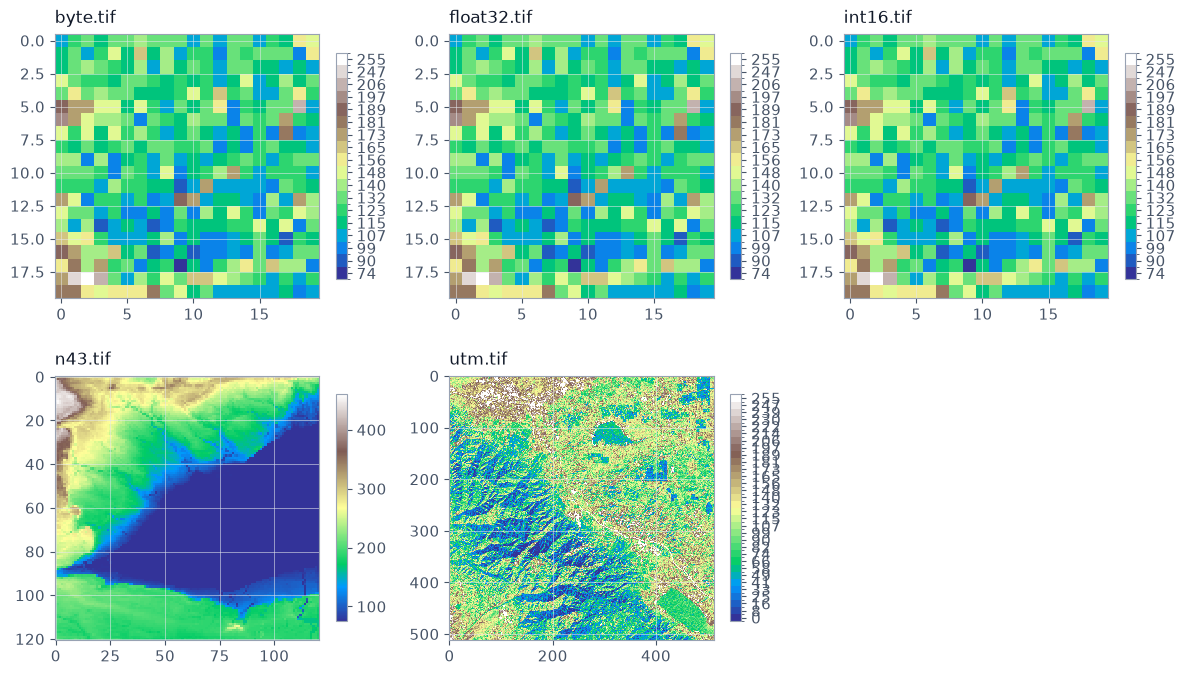

(<Figure size 1200x700 with 11 Axes>,
 array([[<Axes: title={'left': 'byte.tif'}>,
         <Axes: title={'left': 'float32.tif'}>,
         <Axes: title={'left': 'int16.tif'}>],
        [<Axes: title={'left': 'n43.tif'}>,
         <Axes: title={'left': 'utm.tif'}>, <Axes: >]], dtype=object))

In [3]:
# Classic single-band GeoTIFF samples from the GDAL autotest tree.
geotiffs = [
    SAMPLES / "byte.tif",  # 8-bit integer grid
    SAMPLES / "float32.tif",  # 32-bit float grid
    SAMPLES / "int16.tif",  # 16-bit signed integer grid
    SAMPLES / "n43.tif",  # USGS DEM-style GeoTIFF
    SAMPLES / "utm.tif",  # larger UTM-projected grid
]

# Hold pixel arrays for a multi-panel plot.
arrays = []
# Hold panel titles aligned with arrays.
titles = []
# Open each GeoTIFF, print metadata, and collect the pixel array.
for path in geotiffs:
    # Open the raster and release the handle when done.
    with open_raster_data(path) as dataset:
        # Print one-line metadata for this file.
        summarize(path, dataset)
        # Append the full bands-first array.
        arrays.append(dataset.read())
        # Keep the file name as the panel title.
        titles.append(path.name)

# Draw all single-band GeoTIFFs in a shared grid.
plot_rasters(arrays, titles=titles, ncols=3, figsize=(12, 7), cmap="terrain")


### RGB GeoTIFF

`rgbsmall.tif` and `small_world.tif` are three-band images. `dataset.read()` returns
shape `(bands, rows, columns)`. The helper above maps that to display RGB.


rgbsmall.tif                  driver=GTiff     size=50x50  bands=3  crs=EPSG:4326


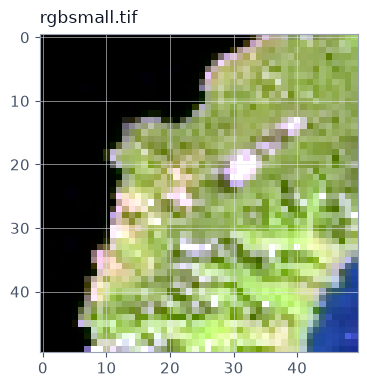

small_world.tif               driver=GTiff     size=400x200  bands=3  crs=EPSG:4326


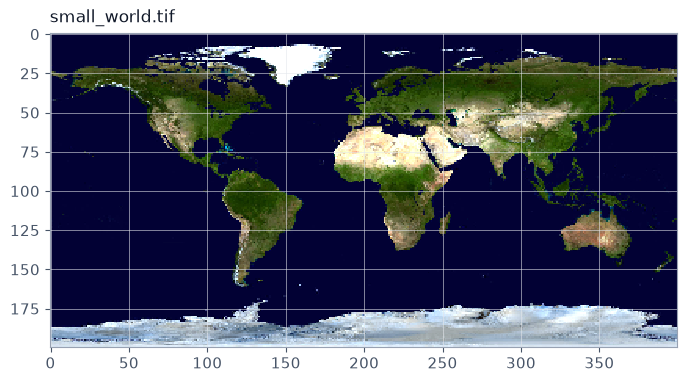

In [4]:
# Open and plot the two three-band RGB GeoTIFF samples.
for path in [SAMPLES / "rgbsmall.tif", SAMPLES / "small_world.tif"]:
    # Print metadata and draw RGB via read_and_show.
    read_and_show(path, figsize=(7, 4))


### Windowed read

Pass `window=(xoff, yoff, xsize, ysize)` to `dataset.read` to load only a pixel window.
That keeps memory low on large tiles.


full=(512, 512)  window=(100, 100, 128, 128)  chip=(128, 128)


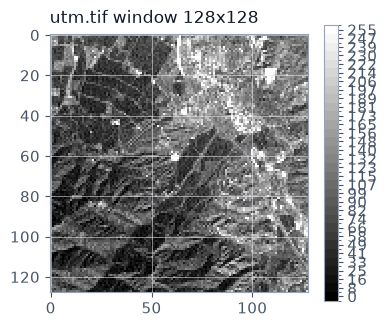

In [5]:
# Open the larger UTM GeoTIFF for a windowed read demo.
with open_raster_data(SAMPLES / "utm.tif") as dataset:
    # Pixel window as (xoff, yoff, xsize, ysize).
    window = (100, 100, 128, 128)
    # Load only that chip instead of the full grid.
    chip = dataset.read(window=window)
    # Compare full shape, requested window, and returned chip shape.
    print(f"full={dataset.shape}  window={window}  chip={chip.shape}")
    # Plot the chip as a grayscale map.
    plot_raster(chip, title="utm.tif window 128x128", cmap="gray", figsize=(4, 4))


## PNG, JPEG, and GIF

Image formats open the same way. Georeferencing may come from a world file
(`.wld` / `.pgw`) or be absent. `png/test.png` ships with `test.wld`.


test.png                      driver=PNG       size=400x400  bands=1  crs=None


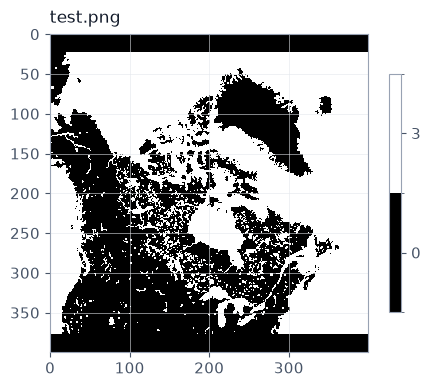

rgbsmall_rgb.jpg              driver=JPEG      size=50x50  bands=3  crs=None


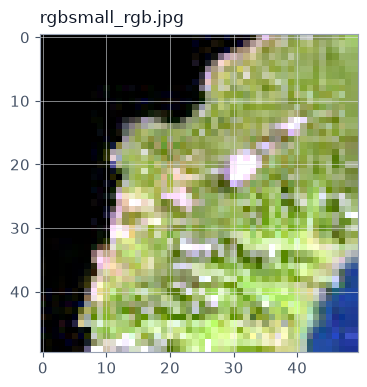

albania.jpg                   driver=JPEG      size=361x260  bands=3  crs=None


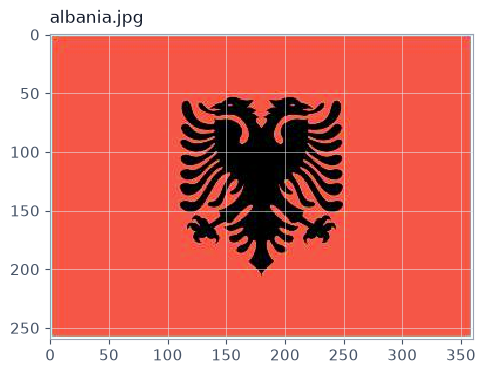

bug407.gif                    driver=GIF       size=400x400  bands=1  crs=None


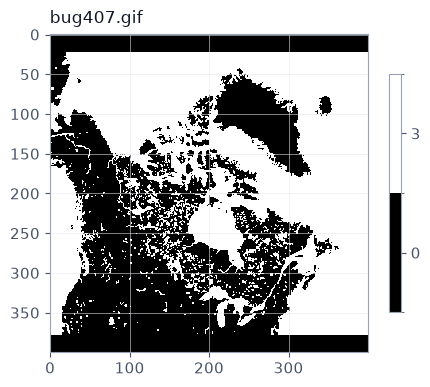

In [6]:
# Image-format samples (PNG with world file, JPEG, GIF).
image_paths = [
    SAMPLES / "png" / "test.png",  # PNG plus companion .wld
    SAMPLES / "jpeg" / "rgbsmall_rgb.jpg",  # small RGB JPEG
    SAMPLES / "jpeg" / "albania.jpg",  # larger JPEG sample
    SAMPLES / "gif" / "bug407.gif",  # GIF sample
]
# Open, summarize, and plot each image.
for path in image_paths:
    # Use gray cmap when the helper falls back to a single band.
    read_and_show(path, cmap="gray", figsize=(5, 4))


## ESRI ASCII Grid, Erdas Imagine, ENVI, USGS DEM

These are common desktop GIS and remote-sensing formats. Open the **data** file for ENVI
(`.img` / `.dat`), not the `.hdr` header.


pixel_per_line.asc            driver=AAIGrid   size=15x12  bands=1  crs=PROJCS["unnamed",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",59],PARAMETER["longitude_of_center",-132.5],PARAMETER["standard_parallel_1",61.6666666666667],PARAMETER["standard_parallel_2",68],PARAMETER["false_easting",500000],PARAMETER["false_northing",500000],UNIT["METERS",1],AXIS["Easting",EAST],AXIS["Northing",NORTH]]


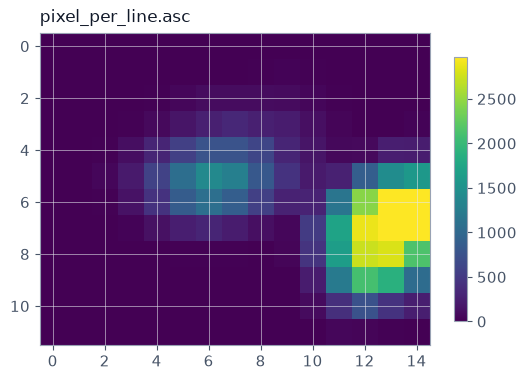

dem10.img                     driver=HFA       size=87x210  bands=1  crs=EPSG:26715


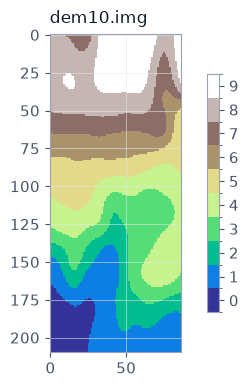

envi_rgbsmall_bsq.img         driver=ENVI      size=50x49  bands=3  crs=EPSG:4326


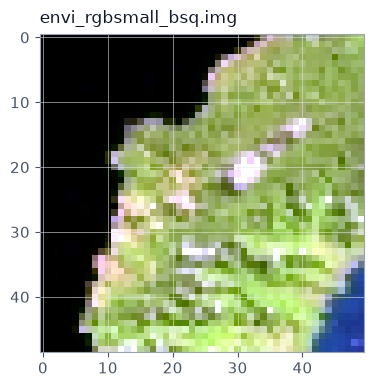

39079G6_truncated.dem         driver=USGSDEM   size=2x470  bands=1  crs=PROJCS["unnamed",GEOGCS["WGS 72",DATUM["World_Geodetic_System_1972",SPHEROID["WGS 72",6378135,298.26,AUTHORITY["EPSG","7043"]],AUTHORITY["EPSG","6322"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4322"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-81],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]


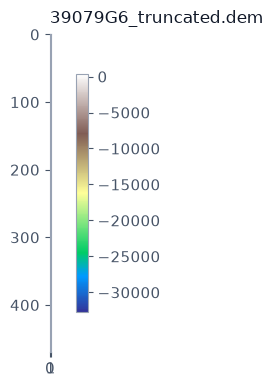

In [7]:
# Desktop GIS / remote-sensing formats with a preferred colormap each.
other_paths = [
    (SAMPLES / "aaigrid" / "pixel_per_line.asc", "viridis"),  # ESRI ASCII Grid
    (SAMPLES / "hfa" / "dem10.img", "terrain"),  # Erdas Imagine DEM
    (SAMPLES / "envi" / "envi_rgbsmall_bsq.img", "viridis"),  # ENVI BSQ (data file, not .hdr)
    (SAMPLES / "usgsdem" / "39079G6_truncated.dem", "terrain"),  # USGS DEM
]
# Open, summarize, and plot each format with its colormap.
for path, cmap in other_paths:
    # Pass figsize so panels stay compact in the notebook.
    read_and_show(path, cmap=cmap, figsize=(5.5, 4))


## Writing rasters

`write_raster_data` picks the driver from the file extension (or from `driver=`).
`write_geotiff`, `write_png`, and `write_jpeg` fix the driver. Pass `overwrite=True`
to replace an existing file.

The next cells copy the classic `byte.tif` grid into several formats under
`Data/00_shared/raster_data/output_folder`, then write a compressed tiled GeoTIFF of `utm.tif`.


In [8]:
# Open the classic byte.tif sample as the write source.
with open_raster_data(SAMPLES / "byte.tif") as src:
    # Load all bands into a NumPy array.
    byte = src.read()
    # Keep the affine geotransform for written copies.
    byte_gt = src.geotransform
    # Keep the CRS string / WKT for written copies.
    byte_crs = src.crs
    # Keep band-1 nodata so GeoTIFF / ASCII preserve it.
    byte_nodata = src.get_band(1).nodata

# Map of output file name -> written path for the verify loop below.
written = {}
# Write a compressed, tiled GeoTIFF copy.
written["byte_copy.tif"] = write_geotiff(
    OUTPUT / "byte_copy.tif",  # destination path
    byte,  # pixel array
    crs=byte_crs,  # CRS from the source
    geotransform=byte_gt,  # geotransform from the source
    nodata=byte_nodata,  # nodata from band 1
    overwrite=True,  # replace an existing file
    creation_options={"COMPRESS": "LZW", "TILED": "YES"},  # LZW + tiles
)
# Write an 8-bit PNG (cast required for PNG).
written["byte.png"] = write_png(OUTPUT / "byte.png", byte.astype(np.uint8), overwrite=True)
# Write an 8-bit JPEG.
written["byte.jpg"] = write_jpeg(OUTPUT / "byte.jpg", byte.astype(np.uint8), overwrite=True)

# Write an ESRI ASCII Grid via the generic writer.
written["byte.asc"] = write_raster_data(
    OUTPUT / "byte.asc",  # destination path
    byte.astype(np.float32),  # AAIGrid expects floating values
    driver="AAIGrid",  # force the ASCII Grid driver
    crs=byte_crs,  # CRS from the source
    geotransform=byte_gt,  # geotransform from the source
    nodata=-9999,  # ASCII nodata sentinel
    overwrite=True,  # replace an existing file
)

# Write an Erdas Imagine .img via the generic writer.
written["byte.img"] = write_raster_data(
    OUTPUT / "byte.img",  # destination path
    byte,  # pixel array
    driver="HFA",  # Erdas Imagine driver
    crs=byte_crs,  # CRS from the source
    geotransform=byte_gt,  # geotransform from the source
    overwrite=True,  # replace an existing file
)

# Re-open each written file and print one-line metadata.
for name, path in written.items():
    # Confirm the file opens and report driver / size / CRS.
    with read_raster_data(path) as dataset:
        # Print driver / size / CRS for this written path.
        summarize(path, dataset)


byte_copy.tif                 driver=GTiff     size=20x20  bands=1  crs=EPSG:26711
byte.png                      driver=PNG       size=20x20  bands=1  crs=None
byte.jpg                      driver=JPEG      size=20x20  bands=1  crs=None
byte.asc                      driver=AAIGrid   size=20x20  bands=1  crs=PROJCS["NAD27 / UTM zone 11N",GEOGCS["NAD27",DATUM["North_American_Datum_1927",SPHEROID["Clarke 1866",6378206.4,294.978698213898,AUTHORITY["EPSG","7008"]],AUTHORITY["EPSG","6267"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
byte.img                      driver=HFA       size=20x20  bands=1  crs=EPSG:26711


In [9]:
# Open utm.tif and write a Deflate-compressed tiled GeoTIFF copy.
with open_raster_data(SAMPLES / "utm.tif") as src:
    # Pass the open RasterDataset so write_geotiff can copy metadata.
    write_geotiff(
        OUTPUT / "utm_deflate.tif",  # destination path
        src,  # open dataset as the pixel/metadata source
        overwrite=True,  # replace an existing file
        creation_options={"COMPRESS": "DEFLATE", "TILED": "YES", "PREDICTOR": "2"},  # Deflate + tiles
    )

# Open the small RGB GeoTIFF and write GeoTIFF + JPEG copies.
with open_raster_data(SAMPLES / "rgbsmall.tif") as src:
    # Load the three-band stack (bands-first).
    rgb = src.read()
    # Write a photometric-RGB GeoTIFF with LZW compression.
    write_geotiff(
        OUTPUT / "rgbsmall_copy.tif",  # destination path
        rgb,  # RGB array
        crs=src.crs,  # CRS from the source
        geotransform=src.geotransform,  # geotransform from the source
        overwrite=True,  # replace an existing file
        creation_options={"PHOTOMETRIC": "RGB", "COMPRESS": "LZW"},  # RGB + LZW
    )
    # Write a JPEG from the same RGB stack.
    write_jpeg(OUTPUT / "rgbsmall_copy.jpg", rgb, overwrite=True)

# List every file now present under OUTPUT with its size.
print("Wrote:")
# Sort for stable notebook output.
for path in sorted(OUTPUT.glob("*")):
    # Skip nested directories if any appear later.
    if path.is_file():
        # Print name padded to 24 chars and size in bytes.
        print(f"  {path.name:24} {path.stat().st_size:8d} bytes")


Wrote:
  byte.asc                     1725 bytes
  byte.img                    10721 bytes
  byte.jpg                      338 bytes
  byte.jpg.aux.xml              350 bytes
  byte.png                      372 bytes
  byte.png.aux.xml              208 bytes
  byte.prj                      431 bytes
  byte_copy.tif                1124 bytes
  rgbsmall_copy.jpg            1186 bytes
  rgbsmall_copy.jpg.aux.xml      808 bytes
  rgbsmall_copy.tif            7107 bytes
  utm_deflate.tif            167519 bytes


## Round-trip check

Re-open the written GeoTIFF and confirm the pixels match the source array.


byte_copy.tif matches byte.tif pixels


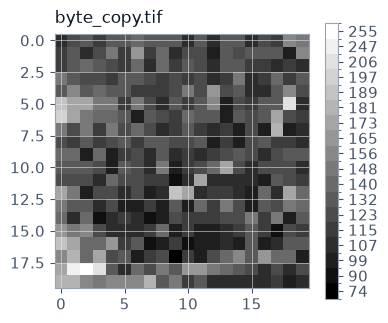

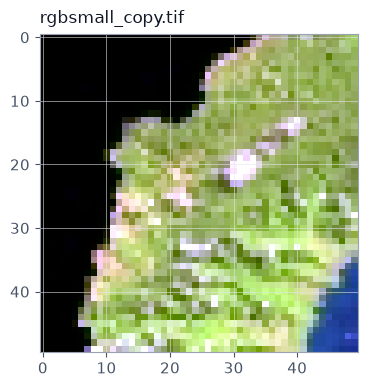

In [10]:
# Re-open the written GeoTIFF copy of byte.tif.
with read_raster_data(OUTPUT / "byte_copy.tif") as dataset:
    # Load all bands for the pixel equality check.
    roundtrip = dataset.read()

# Assert every pixel matches the in-memory source array from cell 18.
np.testing.assert_array_equal(roundtrip, byte)
# Confirm success in the notebook output.
print("byte_copy.tif matches byte.tif pixels")
# Plot the round-tripped grid.
display_array(roundtrip, title="byte_copy.tif", cmap="gray", figsize=(4, 4))

# Re-open and plot the written RGB GeoTIFF copy.
with read_raster_data(OUTPUT / "rgbsmall_copy.tif") as dataset:
    # Draw RGB via the same display helper.
    display_array(dataset.read(), title="rgbsmall_copy.tif", figsize=(4, 4))


## Summary

- `open_raster_data(path)` / `read_raster_data(path)` open any registered GDAL raster
  driver and return a `RasterDataset`.
- Use a `with` block so the GDAL handle is released.
- `dataset.read()` returns a NumPy array; add `window=` for a subset.
- `write_raster_data` / `write_geotiff` / `write_png` / `write_jpeg` write arrays or
  copy an open `RasterDataset`.
- Sample inputs: `Data/00_shared/raster_data/gdal_samples` (from
  [GDAL gdrivers/data](https://github.com/OSGeo/gdal/tree/master/autotest/gdrivers/data)).
- Written outputs: `Data/00_shared/raster_data/output_folder`.
